# Mathematically verified sequential nudge OED — Phase 1

**For `active_inertial_id` | executable mathematical checks and synthetic validation**

This notebook builds a **local, instantaneous-contact, Gaussian/Laplace OED model**, compatible with the impulse and inertia conventions in `src/inertial_identifier.py`. It does **not** claim to optimize a full MuJoCo contact trajectory, robust CBF viability, or observation-window duration. Those require additional dynamics and uncertainty propagation (see the final section).

The critical modeling decision is to treat **measured post-contact velocity changes** as the random observations, not to treat a regression whose columns contain noisy angular rates as though its design matrix were error-free.

Definitions (body-frame quantities unless marked world):

- Target parameter vector $\theta=[m,I_{xx},I_{yy},I_{zz},I_{xy},I_{xz},I_{yz},\rho_x,\rho_y,\rho_z]^T$, where $\rho$ points from CoM to geometric center.
- Contact position $p_{G}$ is expressed relative to the **geometric center**; contact lever from CoM is $r=p_G+\rho$.
- Applied impulse $J_B=R^T J_W$ is taken as **known** for the baseline derivation.
- Ideal instantaneous-contact laws, with negligible external disturbance impulse and negligible change in $R$ during contact:

$$\Delta v_W=J_W/m,\qquad \Delta\omega_B=I_B^{-1}\left[(p_G+\rho)\times J_B\right].$$

These expressions follow directly from $m\Delta v=J$ and $I\Delta\omega=r\times J$. The inertia in this notebook is symmetric and positive definite. No camera-derived shape map or contact friction cone is assumed valid; candidate contact directions are illustrative geometry **only**.

**Measurement model:** $y=[\Delta v_W^T,\Delta\omega_B^T]^T=h(\theta,u)+\epsilon$, with $\epsilon\sim\mathcal N(0,\Sigma_y)$. For an accurate full-flight model, use noisy pre- and post-states, impulse-wrench error, correlations, changing orientation, and process noise.

## 1. Analytical measurement Jacobian

Write $M(\omega)\theta_I=I(\theta_I)\omega$, exactly as implemented in the repository. For $\eta=\Delta\omega_B=I^{-1}(r\times J_B)$, differentiate the implicit equation $I\eta=r\times J_B$:

$$dI\,\eta+I\,d\eta=dr\times J_B.$$

Therefore (holding commanded impulse and planned contact point fixed),

$$\boxed{\frac{\partial \Delta v}{\partial m}=-\frac{J_W}{m^2}}$$

$$\boxed{\frac{\partial\eta}{\partial\theta_I}=-I^{-1}M(\eta)}$$

$$\boxed{\frac{\partial\eta}{\partial\rho}=-I^{-1}[J_B]_{\times}}$$

where $[J]_{\times} x=J\times x$, so $dr\times J=-[J]_{\times}dr$.

**Units matter.** We use dimensionless local perturbations $z=D^{-1}(\theta-\bar\theta)$ and $H=\partial h/\partial z=(\partial h/\partial\theta)D$, with $D$ the diagonal prior standard deviations. This makes ranks, weak directions, and E-optimality interpretable in physically weighted coordinates.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Works from repo root or from repo/notebooks. Copy this notebook to notebooks/.
root = Path.cwd()
if not (root / "src" / "inertial_identifier.py").exists():
    root = root.parent
if not (root / "src" / "inertial_identifier.py").exists():
    raise FileNotFoundError("Run inside active_inertial_id repo or its notebooks/ directory")
sys.path.insert(0, str(root))
from src.inertial_identifier import (inertia_design_matrix, theta_to_inertia,
                                      inertia_to_theta, skew)

np.set_printoptions(precision=5, suppress=True)

# I_ref is a physically admissible SYNTHETIC nominal matrix from the estimator's self-test.
# This is a unit-test scenario, not target truth available to a flight planner.
I_ref = np.array([[70.4168,-2.9396,0.6888],[-2.9396,69.8541,2.3643],[0.6888,2.3643,58.3635]])
m_ref = 638.027
rho_ref = np.array([0.03,-0.02,0.015])    # demonstration offset, m
parameter_mean = np.r_[m_ref,inertia_to_theta(I_ref),rho_ref]
parameter_std = np.r_[60., [7.,7.,7.,3.,3.,3.], [.04,.04,.04]]
D = np.diag(parameter_std)

# Noise configured in experiments/single_nudge_experiment_asteroid_cbf.py.
# Two independent raw state samples -> noise on a difference is sqrt(2) times raw noise.
sigma_v = np.sqrt(2)*1e-4                         # m/s, idealized 1 pre + 1 post
sigma_omega = np.sqrt(2)*np.deg2rad(1e-4)        # rad/s, idealized 1 pre + 1 post
Sigma = np.diag([sigma_v**2]*3+[sigma_omega**2]*3)
Sigma_inv = np.diag(1/np.diag(Sigma))
Lwhite = np.diag(1/np.sqrt(np.diag(Sigma)))
print('Imported repository inertia tensor regressor')
print('posterior noise standard deviations:',sigma_v,'m/s; ',sigma_omega,'rad/s')


Imported repository inertia tensor regressor
posterior noise standard deviations: 0.0001414213562373095 m/s;  2.4682682989768705e-06 rad/s


In [2]:
def physical_response(theta, p_geo, J_world, R=np.eye(3)):
    m = theta[0]
    I = theta_to_inertia(theta[1:7])
    rho = theta[7:10]
    Jbody = R.T @ J_world
    lever = p_geo + rho
    Lbody = np.cross(lever, Jbody)
    dw = np.linalg.solve(I, Lbody)
    return np.r_[J_world/m, dw]

def physical_jacobian(theta, p_geo, J_world, R=np.eye(3)):
    m = theta[0]
    I = theta_to_inertia(theta[1:7])
    eta = physical_response(theta,p_geo,J_world,R)[3:]
    Jbody = R.T @ J_world
    G = np.zeros((6,10))
    G[:3,0] = -J_world/m**2
    G[3:,1:7] = -np.linalg.solve(I, inertia_design_matrix(eta))
    G[3:,7:] = -np.linalg.solve(I, skew(Jbody))
    return G

def finite_difference_jac(theta,p_geo,J_world,h=2e-5):
    # Differentiate with respect to dimensionless z, to avoid bad relative steps.
    J = np.zeros((6,10))
    for k in range(10):
        delta = h*D[:,k]
        J[:,k] = (physical_response(theta+delta,p_geo,J_world)
                 -physical_response(theta-delta,p_geo,J_world))/(2*h)
    return J

test_p = np.array([.45,.17,.12]); test_J = np.array([-3.4,1.2,0.75])
H_an = physical_jacobian(parameter_mean,test_p,test_J)@D
H_fd = finite_difference_jac(parameter_mean,test_p,test_J)
err = np.max(np.abs(Lwhite@(H_an-H_fd)))
print(f'finite-difference maximum whitened derivative discrepancy: {err:.3e}')
assert np.allclose(Lwhite@H_an, Lwhite@H_fd, rtol=1e-7, atol=1e-6)
print('PASS: analytical instantaneous response Jacobian agrees with finite differences.')


finite-difference maximum whitened derivative discrepancy: 3.516e-08
PASS: analytical instantaneous response Jacobian agrees with finite differences.


## 2. Sequential Bayesian Fisher information and *new* information

Let $P_k$ be the parameter covariance after all accepted previous nudges (in dimensionless $z$ coordinates). For candidate $u$ with Jacobian $H_u$ and covariance $\Sigma_u$:

$$F_u=H_u^T\Sigma_u^{-1}H_u,\qquad
P_{k+1}(u)=(P_k^{-1}+F_u)^{-1}.$$

The Gaussian **conditional expected information gain**, measured in nats, is

$$\boxed{\mathrm{EIG}(u\mid\mathcal D_k)=\tfrac12\left[\log\det P_k-\log\det P_{k+1}(u)\right]=\tfrac12\log\det\left(I+P_k^{1/2}F_uP_k^{1/2}\right).}$$

We use a Cholesky factor in code for stable evaluation. Maximizing this uses **remaining uncertainty**, unlike simply maximizing $\|\Delta\omega\|$ or the raw determinant of one candidate's unregularized information matrix.

C-optimality for a scalar $c^T z$ minimizes $c^T P_{k+1}c$; E-optimality improves the least-informed eigen-direction of the *normalized* posterior precision. If CoM offset is a nuisance parameter, the covariance of the mass/inertia block is the **marginal** posterior block $[P_{k+1}]_{1:7,1:7}$; equivalently its precision is the Schur complement $\Lambda_{aa}-\Lambda_{ab}\Lambda_{bb}^{-1}\Lambda_{ba}$.

**Limits of this statement:** EIG equals mutual information *exactly* for a linear-Gaussian observation model with known covariance and Gaussian prior. Here the inverse-inertia response is nonlinear; linearization yields a **local Gaussian/Laplace approximation**, not an exact global Bayesian information gain.

In [3]:
def info_matrix(theta,p,J):
    H = physical_jacobian(theta,p,J)@D
    return (Lwhite@H).T @ (Lwhite@H)

def update_cov(P, F):
    return np.linalg.inv(np.linalg.inv(P)+F)

def expected_gain(P,F):
    L = np.linalg.cholesky(P)
    sign, logdet = np.linalg.slogdet(np.eye(len(P)) + L.T @ F @ L)
    assert sign>0
    return 0.5*logdet

def target_mass_var(P):
    return parameter_std[0]**2 * P[0,0]

P0=np.eye(10)  # prior covariance in z coordinates, independent components assumed for demo
Ftest=info_matrix(parameter_mean,test_p,test_J)
Ptest=update_cov(P0,Ftest)
gain=expected_gain(P0,Ftest)
alt = .5*(np.linalg.slogdet(P0)[1]-np.linalg.slogdet(Ptest)[1])
assert np.isclose(gain,alt,rtol=1e-10,atol=1e-9)
assert np.linalg.eigvalsh(P0-Ptest).min() > -1e-9
print(f'EIG calculation checks: gain={gain:.4f} nats = covariance logdet reduction / 2')
print(f'mass standard deviation: {np.sqrt(target_mass_var(P0)):.2f} -> {np.sqrt(target_mass_var(Ptest)):.2f} kg')


EIG calculation checks: gain=21.6273 nats = covariance logdet reduction / 2
mass standard deviation: 60.00 -> 15.13 kg


/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: divide by zero encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: overflow encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: invalid value encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:10: RuntimeWarning: divide by zero encountered in matmul
  sign, logdet = np.linalg.slogdet(np.eye(len(P)) + L.T @ F @ L)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:10: RuntimeWarning: overflow encountered in matmul
  sign, logdet = np.linalg.slogdet(np.eye(len(P)) + L.T @ F @ L)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:10: RuntimeWarning: in

## 3. Rank and projection operators

For an individual *instantaneous* impulse with known $L$, the inertia regression is $M(\Delta\omega)\theta_I=L$. Since $M\in\mathbb R^{3\times6}$, its rank is at most 3: one pre/post impulse pair **cannot** determine six independent inertia components without additional assumptions.

Two linearly independent $\Delta\omega$ directions generically give rank 5: a symmetric perturbation $\delta I=c nn^T$ with $n$ perpendicular to both leaves both observations unchanged. Three linearly independent directions give full rank 6 (in the ideal noise-free model).

If $W$ is the whitened and parameter-scaled **stacked** regression, $W=U\Sigma V^T$, the observable directions are its well-excited right singular vectors. $P_{\mathrm{null}}=I-W^+W$ projects onto the *exact numerical nullspace* of $W$; weak but nonzero directions require a singular-value threshold, not binary nullspace labeling. Free-flight tumbling can add independent dynamical equations after a **single physical nudge**; do not confuse observation rows with independent impulses.

In [4]:
def inertia_instantaneous_stack(deltas):
    return np.vstack([inertia_design_matrix(v) for v in deltas])
e1,e2,e3=np.eye(3)
W1=inertia_instantaneous_stack([e1])
W2=inertia_instantaneous_stack([e1,e2])
W3=inertia_instantaneous_stack([e1,e2,e3])
print('instantaneous inertia rank for 1,2,3 independent angular increments:',
      [np.linalg.matrix_rank(A) for A in (W1,W2,W3)])
assert [np.linalg.matrix_rank(A) for A in (W1,W2,W3)] == [3,5,6]
Wplus=np.linalg.pinv(W2)
Pnull=np.eye(6)-Wplus@W2
assert np.allclose(Pnull,Pnull.T,atol=1e-12)
assert np.allclose(Pnull@Pnull,Pnull,atol=1e-12)
assert np.allclose(W2@Pnull,0,atol=1e-12)
print('PASS: exact nullspace projection is symmetric, idempotent, and annihilated by W')


instantaneous inertia rank for 1,2,3 independent angular increments: [np.int64(3), np.int64(5), np.int64(6)]
PASS: exact nullspace projection is symmetric, idempotent, and annihilated by W


## 4. Contact candidate set and rigorous magnitude limitation

Generate illustrative **spherical** contact geometry: $p_G=0.50n$ for unit outward normal $n$, and an inward/tangential push $\hat d=-\sqrt{1-\alpha^2}n+\alpha t$, $\alpha=0.30$ (matching the config's tangential fraction). The sphere is a surrogate for candidate generation, **not** a verified geometric model for your asteroid mesh.

For fixed $p_G$, $\rho$, $\hat d$, and locally fixed covariance, response sensitivity $H\propto j$ when $J=j\hat d$. Thus $F(j)=j^2F(1)$. A pure information maximum tends to use the highest permissible impulse. A **minimum-effective impulse** needs a different objective:

$$\min_{u} \|J(u)\|\quad\text{s.t.}\quad\mathrm{EIG}(u\mid\mathcal D_k)\geq\gamma,$$

plus peak force, contact feasibility, servicer dynamics, path-wise safety, and post-nudge recovery constraints. An impulse-only filter is **not** a CBF or backward-reachability certificate.

In [5]:
def normalize(v):
    return v/np.linalg.norm(v)

def choose_tangent(n):
    reference = np.array([0.,0.,1.])
    if abs(n@reference)>.87:
        reference=np.array([0.,1.,0.])
    return normalize(reference-(reference@n)*n)

normals=[np.array(v,dtype=float) for v in [
    [1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1],
    [1,1,0],[1,0,1],[0,1,1],[-1,1,1]]]

candidates=[]
for k,raw in enumerate(normals):
    normal=normalize(raw)
    tangent=choose_tangent(normal)
    direction=normalize(-np.sqrt(1-.3**2)*normal+.3*tangent)
    for j in [1.5,3.,5.]:
        # All pass simple constant 3 N contact-force dwell <= 6 s and j <= 15 Ns.
        candidates.append(dict(name=f'N{k}: {j:.1f} Ns',p=.5*normal,
                               J=j*direction,mag=j,dwell=j/3.,normal=normal))

assert all(c['mag']<=15 and c['dwell']<=6 and
           c['J']@c['normal']<0 for c in candidates)

# Verify J^2 scaling for a fixed direction; this holds only for the stated local model.
c=candidates[0]
Fhalf=info_matrix(parameter_mean,c['p'],c['J'])
Fdouble=info_matrix(parameter_mean,c['p'],2*c['J'])
assert np.allclose(Fdouble,4*Fhalf,rtol=1e-12,atol=1e-9)
print('PASS: Fisher matrix scales by 4 for double impulse at fixed geometry')


PASS: Fisher matrix scales by 4 for double impulse at fixed geometry


/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: divide by zero encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: overflow encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: invalid value encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)


## 5. Sequential greedy information design vs repeating the same nudge

The table below shows an **illustrative local design** under the synthetic prior and idealized sensor-noise assumptions. This is *not* a claim that any suggested candidate can be reached, safely touched, or recovered from by the actual servicer. Before controlling MuJoCo, the contact planner and CBF/viability tests must reject infeasible candidates.

An OED candidate is scored using the current $P_k$, updated **after** each accepted nudge, so redundant excitation earns progressively less new information. The `repeat` baseline uses the same first selected contact indefinitely.

In [6]:
n_steps=5
chosen=[]
Pg=P0.copy()
Pr=P0.copy()
first=None
record=[]
for k in range(n_steps):
    scored=sorted(((expected_gain(Pg,info_matrix(parameter_mean,c['p'],c['J'])),i)
                  for i,c in enumerate(candidates)), reverse=True)
    gain,i=scored[0]
    cand=candidates[i]
    if first is None:
        first=cand
    Pg=update_cov(Pg,info_matrix(parameter_mean,cand['p'],cand['J']))
    Pr=update_cov(Pr,info_matrix(parameter_mean,first['p'],first['J']))
    chosen.append(cand)
    record.append((k+1,cand['name'],gain,expected_gain(P0,np.linalg.inv(Pg)-np.eye(10)),
                   expected_gain(P0,np.linalg.inv(Pr)-np.eye(10))))
print('step | greedy contact | incremental gain | total greedy gain | total repeated gain (nats)')
for row in record:
    print(f'{row[0]:>4} | {row[1]:>14} | {row[2]:>16.4f} | {row[3]:>17.4f} | {row[4]:>17.4f}')
print('marginal posterior mass / inertia / CoM standard deviations after greedy sequence:')
print((np.sqrt(np.diag(Pg))*parameter_std).round(5))
# At least as informative in total logdet as the particular repeat-only sequence.
assert record[-1][3]+1e-8>=record[-1][4]


step | greedy contact | incremental gain | total greedy gain | total repeated gain (nats)
   1 |     N9: 5.0 Ns |          21.9421 |           21.9421 |           21.9421
   2 |     N5: 5.0 Ns |          18.5368 |           40.4789 |           23.3194
   3 |     N7: 5.0 Ns |          15.4368 |           55.9158 |           24.1274
   4 |     N6: 5.0 Ns |           2.2899 |           58.2057 |           24.7012
   5 |     N8: 5.0 Ns |           1.1761 |           59.3818 |           25.1466
marginal posterior mass / inertia / CoM standard deviations after greedy sequence:
[5.13032 0.01871 0.02687 0.08052 0.00742 0.01146 0.0203  0.00003 0.00004
 0.00006]


/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: divide by zero encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: overflow encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:3: RuntimeWarning: invalid value encountered in matmul
  return (Lwhite@H).T @ (Lwhite@H)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:10: RuntimeWarning: divide by zero encountered in matmul
  sign, logdet = np.linalg.slogdet(np.eye(len(P)) + L.T @ F @ L)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:10: RuntimeWarning: overflow encountered in matmul
  sign, logdet = np.linalg.slogdet(np.eye(len(P)) + L.T @ F @ L)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/2437991646.py:10: RuntimeWarning: in

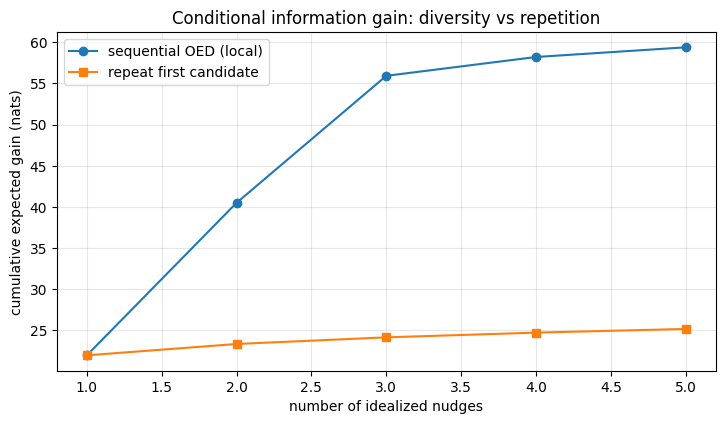

In [7]:
fig,ax=plt.subplots(figsize=(8.5,4.4))
ax.plot([r[0] for r in record],[r[3] for r in record],marker='o',label='sequential OED (local)')
ax.plot([r[0] for r in record],[r[4] for r in record],marker='s',label='repeat first candidate')
ax.set(xlabel='number of idealized nudges',ylabel='cumulative expected gain (nats)',
       title='Conditional information gain: diversity vs repetition')
ax.legend()
ax.grid(True,alpha=.3)
plt.show()


## 6. Why jointly estimating CoM matters: Schur complement

The rotational response $I^{-1}((p_G+\rho)\times J)$ couples the unknown inertia $I$ and unknown CoM offset $\rho$. An optimizer that presumes $\rho$ exact will report overoptimistic inertial precision. With $\Lambda=P^{-1}$ partitioned into interest parameters $a=(m,\theta_I)$ and nuisance $b=\rho$,

$$\Lambda_{a,\mathrm{marginal}}=\Lambda_{aa}-\Lambda_{ab}\Lambda_{bb}^{-1}\Lambda_{ba};\quad
\mathrm{Cov}(a\mid y)=\Lambda_{a,\mathrm{marginal}}^{-1}.$$

This is distinct from $\Lambda_{aa}^{-1}$ (which assumes $\rho$ known exactly). The numerical equality below verifies the block inversion identity.

In [8]:
Precision=np.linalg.inv(Pg)
a=slice(0,7); b=slice(7,10)
Schur=Precision[a,a]-Precision[a,b]@np.linalg.solve(Precision[b,b],Precision[b,a])
P_marginal=np.linalg.inv(Schur)
P_rho_fixed=np.linalg.inv(Precision[a,a])
assert np.allclose(P_marginal,Pg[a,a],rtol=1e-8,atol=1e-9)
assert np.linalg.eigvalsh(P_marginal-P_rho_fixed).min()>-1e-9
print('PASS: Schur complement equals marginalized covariance for mass+inertia')
print('trace of standardized covariance, unknown rho vs known rho:',
      np.trace(P_marginal),np.trace(P_rho_fixed))


PASS: Schur complement equals marginalized covariance for mass+inertia
trace of standardized covariance, unknown rho vs known rho: 0.007531827386254115 0.007409305966747962


## 7. A numerically exact Gaussian validation of information gain

Here we validate the matrix formulas independently of any optimizer. Conditional on fixed local linearization, let an unknown dimensionless parameter perturbation $z\sim\mathcal N(0,I)$ produce stacked measurements $y=Az+\epsilon$ with independently whitened $\epsilon\sim\mathcal N(0,I)$. The posterior has $P=(I+A^TA)^{-1}$. We draw multiple independent synthetic missions, compute the posterior means, and compare the empirical posterior-estimation errors to the **analytically predicted posterior covariance**.

The exactness is for the specified linear-Gaussian surrogate. It is **not** a Monte Carlo verification of the full MuJoCo/vision/contact model. A separate nonlinear estimator test, trajectory integration, and CBF safety stress test are still necessary.

In [9]:
A=np.vstack([Lwhite@physical_jacobian(parameter_mean,c['p'],c['J'])@D for c in chosen])
P_expected=np.linalg.inv(np.eye(10)+A.T@A)
assert np.allclose(P_expected,Pg,rtol=1e-6,atol=1e-8)
K=P_expected@A.T
rng=np.random.default_rng(20261027)
nMC=500
z_true=rng.normal(size=(10,nMC))
obs=A@z_true+rng.normal(size=(A.shape[0],nMC))
z_post=K@obs
error=z_post-z_true
empirical_cov=error@error.T/nMC
# Finite Monte Carlo fluctuations: aggregate trace should lie within ~15% for 500 trials.
rel_trace_err=(np.trace(empirical_cov)-np.trace(P_expected))/np.trace(P_expected)
print('expected trace(P):',np.trace(P_expected))
print('empirical trace(error error^T):',np.trace(empirical_cov))
print('relative difference:',rel_trace_err)
assert abs(rel_trace_err)<0.15
print('PASS: Monte Carlo error agrees with analytic linear-Gaussian covariance within 15%.')


expected trace(P): 0.007535818611552338
empirical trace(error error^T): 0.007071763131175015
relative difference: -0.061579969515976676
PASS: Monte Carlo error agrees with analytic linear-Gaussian covariance within 15%.


/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/517576748.py:2: RuntimeWarning: divide by zero encountered in matmul
  P_expected=np.linalg.inv(np.eye(10)+A.T@A)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/517576748.py:2: RuntimeWarning: overflow encountered in matmul
  P_expected=np.linalg.inv(np.eye(10)+A.T@A)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/517576748.py:2: RuntimeWarning: invalid value encountered in matmul
  P_expected=np.linalg.inv(np.eye(10)+A.T@A)
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/517576748.py:4: RuntimeWarning: divide by zero encountered in matmul
  K=P_expected@A.T
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/517576748.py:4: RuntimeWarning: overflow encountered in matmul
  K=P_expected@A.T
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/517576748.py:4: RuntimeWarning: invalid value encountered in matmul
  K=P_expected@A.T
/var/folders/r4/mh

## 8. Observation duration, safety, and true capture viability: additional equations required

### Time-dependent attitude measurements

A single instantaneous angular-rate increment contains no observation-window duration. To optimize the proposed **adaptive** window $T$, add post-contact Euler free-flight and attitude propagation:

$$I\dot\omega+\omega\times(I\omega)=\tau_{\mathrm{dist}},\qquad \dot R=R[\omega]_{\times},$$

and propagate the sensitivity $S_\theta(t)=\partial x(t)/\partial\theta$:

$$\dot S_\theta=f_x S_\theta+f_\theta,\qquad S_\theta(0)=\frac{\partial x(0)}{\partial\theta}.$$

If $y_k=g(x(t_k),\theta)+\epsilon_k$, the sample sensitivity is $H_k=g_xS_\theta(t_k)+g_\theta$. Then $F_T=H_{0:T}^T\Sigma_{0:T}^{-1}H_{0:T}$, where **shared** pre-nudge and impulse errors require a **non-block-diagonal** $\Sigma_{0:T}$. Pose correlation/filter outputs must also be represented appropriately. Varying $T$ in this expression and assigning a mission/time cost gives an interpretable adaptive duration.

### Translational feasibility bound

Ignoring servicer motion and external disturbances, for one fixed impulse $J$ the target drifts $\Delta r=JT/m$. At $m=638.027$ kg, $J=5$ N·s, and $T=1200$ s, its *translational displacement relative to a stationary origin* is $9.40$ m. This does **not** assert that the CBF shell will be violated, because the servicer's controller actively tracks the target. Instead, it demonstrates the need to constrain **servicer recovery force, thrust, propellant, and reachability** explicitly.

### Safe nudge acceptance

A robust acceptance test should use **uncertainty-aware** post-nudge state tubes and require a feasible servicer control policy satisfying all contact/no-contact phases, collision/CBF constraints, actuator and fuel bounds, and capture envelope. Set membership in a backward reachable set of terminal recovery states is a useful formalization. A one-step CBF admissibility test is not a proof of future recoverability.

### Paired impulses

In an inertial frame, $J_2=-J_1$ produces zero *net linear* impulse. If contact lever arms are fixed in the same frame, the net angular impulse is $(r_1-r_2)\times J_1$, generally nonzero. If $r_1=r_2$ it also cancels. With a rotating target, the two contacts occur at different times/attitudes, so the actual time history must be integrated. Unilateral contact feasibility and safety during the time **between** nudges must be checked.

### Missing physical/measurement validation

- Contact-point location $p_G$, friction coefficient, impact direction and attainable impulse are **uncertain**, not known oracle values.
- Force/torque sensor noise and attitude uncertainty affect both response and impulse reference-frame conversion. Regression with noisy angular rates is an errors-in-variables problem.
- The estimator's repeated shared pre/post impulse rows are correlated; treating them as independent makes covariance overly optimistic.
- Candidate designs based on $\bar\theta$ are **locally optimal**; for a strong claim use robust/worst-case criteria or expected gain across a posterior ensemble, then compare actual estimation error, empirical coverage, and failure rates over Monte Carlo runs.
- Target mass/inertia from MuJoCo XML must remain **ground truth for validation only**, not input to the operational optimizer.

**Suggested integration priority:** (1) validate impulse/Jacobians and correlated noise; (2) rank safe contact proposals by conditional EIG, with nuisance-parameter marginalization; (3) propagate torque-free trajectories and choose observation window; (4) implement robust capture/reachability screening; (5) repeat over successive nudges and verify statistically.


## 9. Existing repository's *single nudge + free-tumble* identification: rank over time

Your experiment intentionally pairs **one** measured impulse with **many** observed post-nudge states. This is mathematically legitimate for extracting additional *independent dynamical constraints* because torque-free inertial angular momentum is conserved:

$$R(t)I\omega_B(t)=H_W=H_W(0^-)+L_W.$$

If initial spin is zero, $H_W=L_W$ and the linear regression at sample time $t_k$ is

$$R(t_k)M(\omega_B(t_k))\theta_I=L_W.$$

Even one nudge can ultimately produce a full-rank stacked inertia regression if the subsequent **asymmetric tumbling** sufficiently excites different attitudes/rates. The question is how long it takes for the **smallest singular value to become large relative to measurement noise**. The following integrates exact torque-free Euler equations with `scipy.integrate.solve_ivp` and verifies (a) angular momentum conservation, (b) the inertia regression, and (c) time-dependent singular values. Here we sample 61 noiseless trajectory points at each duration; we are analyzing **conditioning**, not claiming 61 statistically independent measurement/impulse observations.

Caution: if the target is spinning steadily about a principal axis, or nearly spherical, the free-flight trajectory may lack enough excitation. In that case a complementary second nudge can be necessary, rather than merely waiting longer.

In [10]:
from scipy.integrate import solve_ivp

# Illustrative physical impulse and contact lever, with zero pre-contact angular rate.
J_demo = np.array([-0.03,-0.4,4.99])
r_demo = np.array([0.36,0.23,-0.11])
L_demo = np.cross(r_demo,J_demo)
omega0 = np.linalg.solve(I_ref,L_demo)

def rigid_body_flow(t, state):
    w = state[:3]
    R = state[3:].reshape(3,3)
    dw = np.linalg.solve(I_ref,-np.cross(w,I_ref@w))
    dR = R@skew(w)
    return np.r_[dw,dR.ravel()]

maxT=1200.
sol=solve_ivp(rigid_body_flow,(0,maxT),np.r_[omega0,np.eye(3).ravel()],
              method='DOP853',rtol=1e-10,atol=1e-12,dense_output=True)
assert sol.success

def regression_at_duration(T):
    states=sol.sol(np.linspace(0,T,61)).T
    A=[]; Herrors=[]
    for state in states:
        omega=state[:3]
        R=state[3:].reshape(3,3)
        A.append(R@inertia_design_matrix(omega))
        Herrors.append(np.linalg.norm(R@I_ref@omega-L_demo))
    W=np.vstack(A)
    s=np.linalg.svd(W,compute_uv=False)
    return s,np.max(Herrors),W

horizons=[10.,100.,300.,600.,1200.]
rows=[]
for T in horizons:
    s,err,W=regression_at_duration(T)
    rows.append((T,s[-1],s[0]/s[-1],err))
    assert err<1e-7
    assert np.linalg.norm(W@inertia_to_theta(I_ref)-np.tile(L_demo,61))<1e-6
print('time (s) | sigma_min(W) | cond(W) | max momentum error (N m s)')
for T,smin,cond,err in rows:
    print(f'{T:>8.0f} | {smin:>12.6g} | {cond:>9.3g} | {err:.2e}')
assert rows[-1][2] < rows[0][2]
print('PASS: torque-free momentum conservation and improved numerical observability.')


time (s) | sigma_min(W) | cond(W) | max momentum error (N m s)
      10 |   4.4158e-06 |  6.16e+04 | 3.32e-13
     100 |   0.00045436 |       599 | 5.35e-12
     300 |   0.00422998 |        65 | 6.77e-12
     600 |    0.0109717 |      25.3 | 8.43e-12
    1200 |    0.0271916 |      9.97 | 8.43e-12
PASS: torque-free momentum conservation and improved numerical observability.


/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/3738173337.py:39: RuntimeWarning: divide by zero encountered in matmul
  assert np.linalg.norm(W@inertia_to_theta(I_ref)-np.tile(L_demo,61))<1e-6
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/3738173337.py:39: RuntimeWarning: overflow encountered in matmul
  assert np.linalg.norm(W@inertia_to_theta(I_ref)-np.tile(L_demo,61))<1e-6
/var/folders/r4/mh57kp1943ndjdct51y2cknm0000gn/T/ipykernel_76046/3738173337.py:39: RuntimeWarning: invalid value encountered in matmul
  assert np.linalg.norm(W@inertia_to_theta(I_ref)-np.tile(L_demo,61))<1e-6
